# LightGBM Evaluation — LLOY.L

## Purpose

This notebook consolidates the completed validation experiment for the
LightGBM regression model and compares its results with Ridge Regression
and three predefined baselines.

The notebook reads existing CSV artefacts. It does not train models,
re-run statistical tests, perform backtesting, or access Final Test
observations.

**Status:** validation experiment concluded; no model is authorised for
trading use on the basis of these results.


FileNotFoundError: Required artefact not found: /home/anderjcruz/projects/Quantitative-Trading/notebooks/reports/model_evaluation/LLOY.L/lightgbm_regression/all_models_comparison_metrics.csv

## 1. Experimental protocol

- **Pilot equity:** Lloyds Banking Group (`LLOY.L`), London Stock Exchange.
- **Market data:** Yahoo Finance.
- **Forecast horizons:** 1, 5 and 10 trading sessions.
- **Target:** `Close(t+h) / Open(t+1) - 1`.
- **Features:** lagged close returns over 1, 5, 10 and 20 sessions,
  and rolling close-return volatility over 5, 10 and 20 sessions.
- **Evaluation:** weekly expanding-window validation.
- **Training eligibility:** target labels must have matured by the
  relevant training cutoff; minimum training sample size is 500.
- **Development period:** 24 October 2016 – 20 October 2023.
- **Validation period:** 23 October 2023 – 22 October 2025.
- **Final Test:** reserved and excluded from this experiment.

The target measures gross price return. It excludes transaction costs,
slippage and dividends. Forecast accuracy is not equivalent to trading
profitability.


## 2. Load existing evaluation artefacts

The following cells read only the results already produced by the
completed validation and statistical-comparison scripts.


In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Locate the project root from the current working directory.
# The root must contain both the reports and src directories.
working_directory = Path.cwd().resolve()

ROOT = next(
    (
        candidate
        for candidate in (working_directory, *working_directory.parents)
        if (candidate / "reports").is_dir()
        and (candidate / "src").is_dir()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project root containing both reports and src."
    )

METRICS_PATH = (
    ROOT / "reports/model_evaluation/LLOY.L/lightgbm_regression/"
    "all_models_comparison_metrics.csv"
)
STATISTICS_PATH = (
    ROOT / "reports/model_evaluation/LLOY.L/lightgbm_regression/"
    "all_models_paired_statistical_tests.csv"
)
PREDICTIONS_PATH = (
    ROOT / "reports/model_evaluation/LLOY.L/lightgbm_regression/"
    "all_models_aligned_predictions.csv"
)

for path in (METRICS_PATH, STATISTICS_PATH, PREDICTIONS_PATH):
    if not path.is_file():
        raise FileNotFoundError(f"Required artefact not found: {path}")

metrics = pd.read_csv(METRICS_PATH)
statistical_tests = pd.read_csv(STATISTICS_PATH)
aligned_predictions = pd.read_csv(PREDICTIONS_PATH)

print(f"Metrics rows: {len(metrics):,}")
print(f"Statistical comparisons: {len(statistical_tests):,}")
print(f"Aligned prediction rows: {len(aligned_predictions):,}")

print("\nMetric columns:")
print(metrics.columns.tolist())

print("\nStatistical-test columns:")
print(statistical_tests.columns.tolist())


Metrics rows: 15
Statistical comparisons: 42
Aligned prediction rows: 7,525

Metric columns:
['horizon', 'model', 'sample_size', 'mae', 'rmse', 'directional_accuracy', 'spearman_correlation', 'r_squared']

Statistical-test columns:
['horizon', 'loss', 'model_a', 'model_b', 'sample_size', 'mean_loss_difference_a_minus_b', 'hac_lag', 'hac_long_run_variance', 'hac_standard_error', 'hac_z_statistic', 'hac_p_value', 'bootstrap_ci_95_lower', 'bootstrap_ci_95_upper', 'holm_adjusted_p_value', 'significant_after_holm_5pct']


## 3. Comparative validation metrics

The primary error metrics are MAE and RMSE. Directional accuracy,
Spearman rank correlation and out-of-sample R² are complementary
diagnostics. Each horizon must be interpreted separately.


In [3]:
display(metrics)

print("\nMetrics by horizon:")
if "horizon" in metrics.columns:
    for horizon, group in metrics.groupby("horizon", sort=True):
        print(f"\nHorizon: {horizon}")
        display(group)


,horizon,model,sample_size,mae,rmse,directional_accuracy,spearman_correlation,r_squared
0,1,lightgbm_regression,506,0.009854,0.013752,0.535573,0.105869,-0.020374
1,1,ridge_regression,506,0.009777,0.013688,0.505929,0.040177,-0.010919
2,1,zero_return,506,0.009757,0.013655,0.470356,NaN,-0.006043
3,1,historical_mean,506,0.009759,0.013659,0.498024,-0.097032,-0.006630
4,1,historical_median,506,0.009793,0.013693,0.470356,-0.093345,-0.011557
5,5,lightgbm_regression,502,0.026133,0.035502,0.549801,0.158544,-0.018253
6,5,ridge_regression,502,0.026023,0.035465,0.597610,0.178884,-0.016138
7,5,zero_return,502,0.026485,0.035934,0.386454,NaN,-0.043174
8,5,historical_mean,502,0.026355,0.035839,0.583665,-0.135498,-0.037668
9,5,historical_median,502,0.026620,0.036050,0.436255,-0.126595,-0.049921



Metrics by horizon:

Horizon: 1


,horizon,model,sample_size,mae,rmse,directional_accuracy,spearman_correlation,r_squared
0,1,lightgbm_regression,506,0.009854,0.013752,0.535573,0.105869,-0.020374
1,1,ridge_regression,506,0.009777,0.013688,0.505929,0.040177,-0.010919
2,1,zero_return,506,0.009757,0.013655,0.470356,NaN,-0.006043
3,1,historical_mean,506,0.009759,0.013659,0.498024,-0.097032,-0.006630
4,1,historical_median,506,0.009793,0.013693,0.470356,-0.093345,-0.011557



Horizon: 5


,horizon,model,sample_size,mae,rmse,directional_accuracy,spearman_correlation,r_squared
5,5,lightgbm_regression,502,0.026133,0.035502,0.549801,0.158544,-0.018253
6,5,ridge_regression,502,0.026023,0.035465,0.597610,0.178884,-0.016138
7,5,zero_return,502,0.026485,0.035934,0.386454,NaN,-0.043174
8,5,historical_mean,502,0.026355,0.035839,0.583665,-0.135498,-0.037668
9,5,historical_median,502,0.026620,0.036050,0.436255,-0.126595,-0.049921



Horizon: 10


,horizon,model,sample_size,mae,rmse,directional_accuracy,spearman_correlation,r_squared
10,10,lightgbm_regression,497,0.039940,0.052301,0.492958,0.075672,-0.099903
11,10,ridge_regression,497,0.039124,0.051289,0.561368,0.123284,-0.057729
12,10,zero_return,497,0.039843,0.052158,0.350101,NaN,-0.093884
13,10,historical_mean,497,0.039502,0.051818,0.623742,-0.174932,-0.079656
14,10,historical_median,497,0.040012,0.052286,0.474849,-0.150928,-0.099245


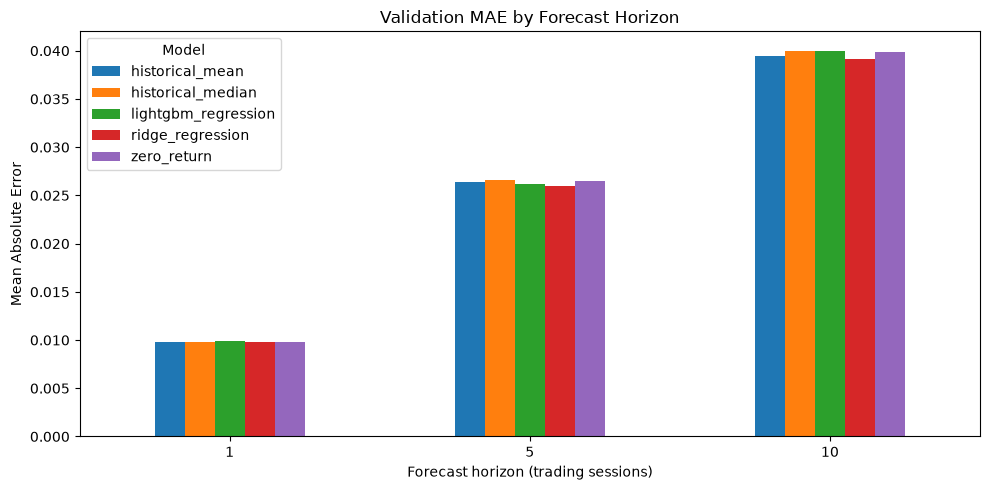

In [4]:
# Plot MAE by horizon using the stored comparison metrics.
required_plot_columns = {"horizon", "model", "mae"}

if required_plot_columns.issubset(metrics.columns):
    plot_data = metrics.pivot(
        index="horizon", columns="model", values="mae"
    ).sort_index()
    ax = plot_data.plot(
        kind="bar",
        figsize=(10, 5),
        title="Validation MAE by Forecast Horizon",
    )
    ax.set_xlabel("Forecast horizon (trading sessions)")
    ax.set_ylabel("Mean Absolute Error")
    ax.legend(title="Model")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
else:
    print(
        "The expected columns were not found. "
        "Inspect the metric table above and adapt the plot to its schema."
    )


## 4. Paired statistical comparisons

The completed analysis compared LightGBM, Ridge Regression and the
predefined baselines using paired loss differences. The procedure
accounted for temporal dependence through HAC/Newey–West inference and
block-bootstrap confidence intervals, with Holm correction across the
predefined family of comparisons.

- Significance level: 5%.
- Bootstrap repetitions: 5,000.
- Bootstrap block length: 10.
- Loss functions: absolute and squared error.
- Comparisons: 42.


In [5]:
display(statistical_tests)

if "significant_after_holm_5pct" in statistical_tests.columns:
    significant = statistical_tests[
        statistical_tests["significant_after_holm_5pct"].astype(bool)
    ]
    print(
        f"Significant comparisons after Holm correction: "
        f"{len(significant)} / {len(statistical_tests)}"
    )
else:
    print(
        "The significance column has a different name or representation. "
        "Inspect the table above before drawing a conclusion."
    )


,horizon,loss,model_a,model_b,sample_size,mean_loss_difference_a_minus_b,hac_lag,hac_long_run_variance,hac_standard_error,hac_z_statistic,hac_p_value,bootstrap_ci_95_lower,bootstrap_ci_95_upper,holm_adjusted_p_value,significant_after_holm_5pct
0,1,absolute,lightgbm_regression,ridge_regression,506,7.708950e-05,10,8.566190e-06,0.000130,0.592484,0.553527,-0.000166,3.349905e-04,1.000000,False
1,1,squared,lightgbm_regression,ridge_regression,506,1.752506e-06,10,1.091147e-08,0.000005,0.377392,0.705882,-0.000007,1.115263e-05,1.000000,False
2,1,absolute,lightgbm_regression,zero_return,506,9.702451e-05,10,7.823277e-06,0.000124,0.780301,0.435214,-0.000127,3.503092e-04,1.000000,False
3,1,squared,lightgbm_regression,zero_return,506,2.656252e-06,10,1.091343e-08,0.000005,0.571958,0.567351,-0.000007,1.217087e-05,1.000000,False
4,1,absolute,lightgbm_regression,historical_mean,506,9.509950e-05,10,7.863719e-06,0.000125,0.762851,0.445552,-0.000141,3.541352e-04,1.000000,False
5,1,squared,lightgbm_regression,historical_mean,506,2.547565e-06,10,1.083372e-08,0.000005,0.550569,0.581929,-0.000007,1.184632e-05,1.000000,False
6,1,absolute,lightgbm_regression,historical_median,506,6.084752e-05,10,7.386614e-06,0.000121,0.503611,0.614535,-0.000166,3.078773e-04,1.000000,False
7,1,squared,lightgbm_regression,historical_median,506,1.634307e-06,10,1.100260e-08,0.000005,0.350478,0.725980,-0.000007,1.083660e-05,1.000000,False
8,1,absolute,ridge_regression,zero_return,506,1.993501e-05,10,9.442858e-07,0.000043,0.461466,0.644464,-0.000061,1.080444e-04,1.000000,False
9,1,squared,ridge_regression,zero_return,506,9.037462e-07,10,6.997830e-10,0.000001,0.768493,0.442194,-0.000001,3.306644e-06,1.000000,False


Significant comparisons after Holm correction: 0 / 42


## 5. Interpretation and decision

### Observed result

No paired comparison was statistically significant after Holm
correction at the 5% level. The evidence does not establish a reliable
statistical advantage for LightGBM or Ridge over the tested baselines.

This is **not proof of model equivalence**. It means that this experiment
did not establish statistically significant differences under the
specified procedure.

### Limitations

1. The experiment concerns one pilot equity, `LLOY.L`.
2. All models had negative out-of-sample R² in the reported comparison.
3. The target is a gross price return and does not include dividends,
   transaction costs, slippage or execution constraints.
4. Forecast metrics do not establish trading profitability.
5. The Final Test was reserved and must not be used for model selection.
6. No backtesting, paper trading or live trading was performed.

### Decision

Conclude the current Ridge and LightGBM validation experiments without
additional tuning. Preserve their results as research evidence and
choose any new model family only after stating a testable hypothesis,
a success criterion and a bounded experimental scope.


## 6. Reproducibility and source artefacts

This notebook consumes the following existing files:

- `reports/model_evaluation/LLOY.L/lightgbm_regression/all_models_comparison_metrics.csv`
- `reports/model_evaluation/LLOY.L/lightgbm_regression/all_models_paired_statistical_tests.csv`
- `reports/model_evaluation/LLOY.L/lightgbm_regression/all_models_aligned_predictions.csv`

The original model evaluation and statistical-test scripts remain the
source of the experimental calculations. This notebook presents and
interprets their saved outputs; it does not reproduce model fitting or
statistical inference.

**Final Test used:** No.  
**Backtesting performed:** No.  
**Trading authorisation granted:** No.
